In [1]:
!pip install biopython


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 30.0 MB/s eta 0:00:00


In [2]:
from Bio.Seq import Seq

dna_sequence = Seq("ATGGCTTACGAACTGCCATGA")

print("DNA Sequence:", dna_sequence)
print("Sequence Length:", len(dna_sequence))

DNA Sequence: ATGGCTTACGAACTGCCATGA
Sequence Length: 21


In [3]:
from Bio.SeqUtils import gc_fraction

gc_content = gc_fraction(dna_sequence) * 100

print("DNA Sequence:", dna_sequence)
print("GC Content:", round(gc_content, 2), "%")

DNA Sequence: ATGGCTTACGAACTGCCATGA
GC Content: 47.62 %


In [4]:
rna_sequence = dna_sequence.transcribe()

print("Original DNA:", dna_sequence)
print("Transcribed RNA:", rna_sequence)

Original DNA: ATGGCTTACGAACTGCCATGA
Transcribed RNA: AUGGCUUACGAACUGCCAUGA


In [5]:
protein_sequence = rna_sequence.translate()

print("DNA Sequence:", dna_sequence)
print("RNA Sequence:", rna_sequence)
print("Protein Sequence:", protein_sequence)

DNA Sequence: ATGGCTTACGAACTGCCATGA
RNA Sequence: AUGGCUUACGAACUGCCAUGA
Protein Sequence: MAYELP*


In [6]:
from Bio.Seq import Seq
from Bio.SeqUtils import gc_fraction

# Example DNA sequence
dna_sequence = Seq("ATGGCTTACGAACTGCCATGA")

# Analyze DNA
sequence_length = len(dna_sequence)
gc_content = gc_fraction(dna_sequence) * 100

# Transcription and translation
rna_sequence = dna_sequence.transcribe()
protein_sequence = rna_sequence.translate()

# Display report
print("DNA SEQUENCE ANALYSIS REPORT")
print("----------------------------")
print("DNA Sequence:", dna_sequence)
print("Sequence Length:", sequence_length, "nucleotides")
print("GC Content:", round(gc_content, 2), "%")
print("RNA Sequence:", rna_sequence)
print("Protein Sequence:", protein_sequence)

DNA SEQUENCE ANALYSIS REPORT
----------------------------
DNA Sequence: ATGGCTTACGAACTGCCATGA
Sequence Length: 21 nucleotides
GC Content: 47.62 %
RNA Sequence: AUGGCUUACGAACUGCCAUGA
Protein Sequence: MAYELP*


In [7]:
report = f"""DNA SEQUENCE ANALYSIS REPORT
----------------------------
DNA Sequence: {dna_sequence}
Sequence Length: {sequence_length} nucleotides
GC Content: {gc_content:.2f}%
RNA Sequence: {rna_sequence}
Protein Sequence: {protein_sequence}
"""

with open("DNA_Sequence_Analysis_Report.txt", "w") as file:
    file.write(report)

print("Report saved successfully!")

Report saved successfully!


In [8]:
with open("DNA_Sequence_Analysis_Report.txt", "r") as file:
    print(file.read())

DNA SEQUENCE ANALYSIS REPORT
----------------------------
DNA Sequence: ATGGCTTACGAACTGCCATGA
Sequence Length: 21 nucleotides
GC Content: 47.62%
RNA Sequence: AUGGCUUACGAACUGCCAUGA
Protein Sequence: MAYELP*



In [9]:
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO

# Create a DNA sequence record
dna_record = SeqRecord(
    dna_sequence,
    id="Example_DNA",
    description="Sample DNA sequence for Biopython analysis"
)

# Save the sequence in FASTA format
SeqIO.write(dna_record, "sample_dna.fasta", "fasta")

print("FASTA file created successfully!")

FASTA file created successfully!


In [10]:
from Bio import SeqIO

# Read the FASTA file
record = SeqIO.read("sample_dna.fasta", "fasta")

# Display sequence information
print("Sequence ID:", record.id)
print("Description:", record.description)
print("DNA Sequence:", record.seq)
print("Sequence Length:", len(record.seq))

Sequence ID: Example_DNA
Description: Example_DNA Sample DNA sequence for Biopython analysis
DNA Sequence: ATGGCTTACGAACTGCCATGA
Sequence Length: 21


In [11]:
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

# Read DNA from FASTA file
record = SeqIO.read("sample_dna.fasta", "fasta")

# Extract DNA sequence
dna = record.seq

# Perform sequence analysis
length = len(dna)
gc = gc_fraction(dna) * 100
rna = dna.transcribe()
protein = dna.translate()

# Display results
print("FASTA SEQUENCE ANALYSIS")
print("-----------------------")
print("Sequence ID:", record.id)
print("DNA Sequence:", dna)
print("Sequence Length:", length)
print("GC Content:", round(gc, 2), "%")
print("RNA Sequence:", rna)
print("Protein Sequence:", protein)

FASTA SEQUENCE ANALYSIS
-----------------------
Sequence ID: Example_DNA
DNA Sequence: ATGGCTTACGAACTGCCATGA
Sequence Length: 21
GC Content: 47.62 %
RNA Sequence: AUGGCUUACGAACUGCCAUGA
Protein Sequence: MAYELP*


In [12]:
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO

# Create three example DNA sequences
sequences = [
    SeqRecord(Seq("ATGGCTTACGAACTGCCATGA"), id="Sequence_1", description=""),
    SeqRecord(Seq("ATGCGTACCGTTAAATAG"), id="Sequence_2", description=""),
    SeqRecord(Seq("ATGAAACCCGGGTTTTAA"), id="Sequence_3", description="")
]

# Save all sequences in one FASTA file
SeqIO.write(sequences, "multiple_sequences.fasta", "fasta")

print("FASTA file with 3 DNA sequences created!")

FASTA file with 3 DNA sequences created!


In [13]:
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

# Read and analyze each DNA sequence
for record in SeqIO.parse("multiple_sequences.fasta", "fasta"):

    dna = record.seq
    length = len(dna)
    gc = gc_fraction(dna) * 100

    print("Sequence ID:", record.id)
    print("DNA Sequence:", dna)
    print("Length:", length)
    print("GC Content:", round(gc, 2), "%")
    print("----------------------------")

Sequence ID: Sequence_1
DNA Sequence: ATGGCTTACGAACTGCCATGA
Length: 21
GC Content: 47.62 %
----------------------------
Sequence ID: Sequence_2
DNA Sequence: ATGCGTACCGTTAAATAG
Length: 18
GC Content: 38.89 %
----------------------------
Sequence ID: Sequence_3
DNA Sequence: ATGAAACCCGGGTTTTAA
Length: 18
GC Content: 38.89 %
----------------------------


In [14]:
import pandas as pd
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

# Create an empty list to store results
results = []

# Analyze each DNA sequence
for record in SeqIO.parse("multiple_sequences.fasta", "fasta"):

    dna = record.seq

    results.append({
        "Sequence_ID": record.id,
        "DNA_Sequence": str(dna),
        "Length": len(dna),
        "GC_Content": round(gc_fraction(dna) * 100, 2)
    })

# Convert results into a table
df = pd.DataFrame(results)

# Display the table
display(df)

,Sequence_ID,DNA_Sequence,Length,GC_Content
0,Sequence_1,ATGGCTTACGAACTGCCATGA,21,47.62
1,Sequence_2,ATGCGTACCGTTAAATAG,18,38.89
2,Sequence_3,ATGAAACCCGGGTTTTAA,18,38.89


In [15]:
# Save the DataFrame as a CSV file
df.to_csv("DNA_Sequence_Analysis_Results.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [16]:
# Read the saved CSV file
saved_results = pd.read_csv("DNA_Sequence_Analysis_Results.csv")

# Display the saved data
display(saved_results)

,Sequence_ID,DNA_Sequence,Length,GC_Content
0,Sequence_1,ATGGCTTACGAACTGCCATGA,21,47.62
1,Sequence_2,ATGCGTACCGTTAAATAG,18,38.89
2,Sequence_3,ATGAAACCCGGGTTTTAA,18,38.89


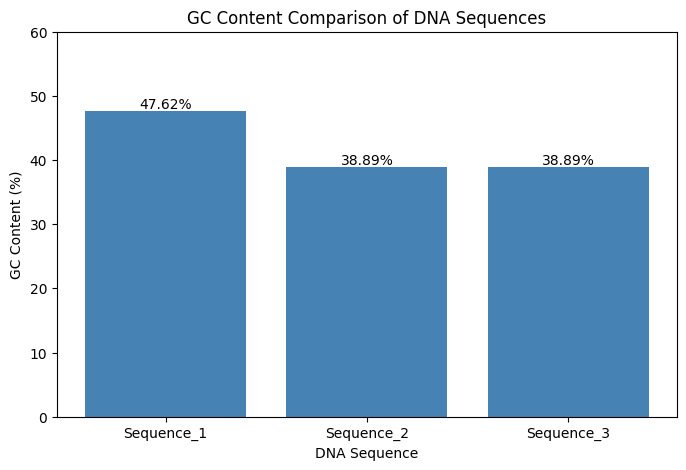

In [17]:
import matplotlib.pyplot as plt

# Create a bar graph
plt.figure(figsize=(8, 5))

plt.bar(df["Sequence_ID"], df["GC_Content"], color="steelblue")

# Add labels and title
plt.xlabel("DNA Sequence")
plt.ylabel("GC Content (%)")
plt.title("GC Content Comparison of DNA Sequences")

# Display GC percentage above each bar
for i, gc in enumerate(df["GC_Content"]):
    plt.text(i, gc + 0.5, f"{gc:.2f}%", ha="center")

plt.ylim(0, 60)
plt.show()

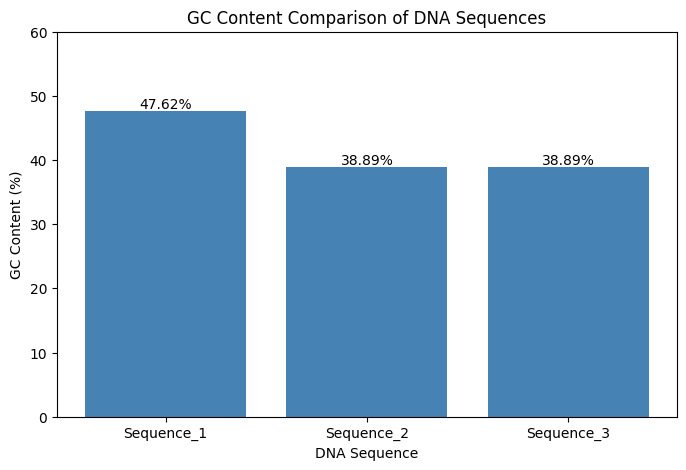

Graph saved successfully!


In [18]:
import matplotlib.pyplot as plt

# Create the graph
plt.figure(figsize=(8, 5))

plt.bar(df["Sequence_ID"], df["GC_Content"], color="steelblue")

plt.xlabel("DNA Sequence")
plt.ylabel("GC Content (%)")
plt.title("GC Content Comparison of DNA Sequences")

# Display percentages above the bars
for i, gc in enumerate(df["GC_Content"]):
    plt.text(i, gc + 0.5, f"{gc:.2f}%", ha="center")

plt.ylim(0, 60)

# Save the graph as a PNG image
plt.savefig("GC_Content_Comparison.png", dpi=300, bbox_inches="tight")

# Display the graph
plt.show()

print("Graph saved successfully!")